# **Insiyab: Crowd Density Estimation**

## **Code Section**

## **1. Import Libraries**

In [ ]:
import os
import glob
import random
import cv2
import numpy as np
import scipy.io as sio
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))  # Runtime > Change runtime type > T4 GPU

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## **2. Settings**

In [ ]:
IMG_H, IMG_W = 384, 512          # Fixed input size for all images
STRIDE = 8                       # The model outputs a map 8x smaller than the input
DEN_H, DEN_W = IMG_H // STRIDE, IMG_W // STRIDE
SIGMA = 1.5                      # Gaussian smoothing for head points
SCALE = 100.0                    # Density maps are multiplied by 100 to help training
PART = "part_A"                  # part_A = very dense crowds, part_B = lighter street scenes
VGG_MEAN = [103.939, 116.779, 123.68]
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## **3. Download ShanghaiTech Dataset**

In [ ]:
# If Kaggle asks for login: kaggle.com > Settings > API > Create New Token, then upload kaggle.json
!pip install -q kagglehub
import kagglehub

DATA_ROOT = kagglehub.dataset_download("tthien/shanghaitech")
print("Dataset path:", DATA_ROOT)

100%|██████████| 333M/333M [00:20<00:00, 17.2MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/tthien/shanghaitech/versions/1


## **4. Match Images with Ground Truth (.mat files)**

In [ ]:
def find_split(split):
    image_paths = sorted(glob.glob(os.path.join(DATA_ROOT, "**", PART, split, "images", "*.jpg"), recursive=True))

    pairs, seen = [], set()
    for img_path in image_paths:
        name = os.path.splitext(os.path.basename(img_path))[0]   # e.g. IMG_1
        gt_path = os.path.join(os.path.dirname(os.path.dirname(img_path)), "ground-truth", f"GT_{name}.mat")

        # Skip missing labels and duplicate copies of the dataset
        if os.path.exists(gt_path) and name not in seen:
            seen.add(name)
            pairs.append((img_path, gt_path))
    return pairs

train_pairs = find_split("train_data")
test_pairs = find_split("test_data")

print("Train images:", len(train_pairs))   # Expected for part_A: 300
print("Test images:", len(test_pairs))     # Expected for part_A: 182

Train images: 300
Test images: 182


## **5. Generate Density Maps from Head Locations**

In [ ]:
def load_points(gt_path):
    mat = sio.loadmat(gt_path)
    return mat["image_info"][0, 0][0, 0][0].astype(np.float32)   # (N, 2) = (x, y)

def make_density(points, orig_h, orig_w):
    density = np.zeros((DEN_H, DEN_W), dtype=np.float32)
    sx, sy = DEN_W / orig_w, DEN_H / orig_h

    for x, y in points:
        cx = min(int(x * sx), DEN_W - 1)
        cy = min(int(y * sy), DEN_H - 1)
        if cx >= 0 and cy >= 0:
            density[cy, cx] += 1.0

    density = gaussian_filter(density, sigma=SIGMA, mode="constant")

    # Keep the total equal to the real number of people
    if density.sum() > 0:
        density *= len(points) / density.sum()
    return density

## **6. Load Images + Density Maps**

In [ ]:
def load_sample(img_path, gt_path):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_W, IMG_H)).astype(np.float32)

    points = load_points(gt_path)
    density = make_density(points, h, w)
    return img, density, len(points)

def load_all(pairs):
    images, densities, counts = [], [], []
    for img_path, gt_path in pairs:
        img, den, count = load_sample(img_path, gt_path)
        images.append(img)
        densities.append(den)
        counts.append(count)
    return np.stack(images), np.stack(densities)[..., None], np.array(counts, dtype=np.float32)

x_train_all, d_train_all, c_train_all = load_all(train_pairs)
x_test, d_test, c_test = load_all(test_pairs)

print("Images:", x_train_all.shape)
print("Density maps:", d_train_all.shape)
print("People per image: min", c_train_all.min(), "| max", c_train_all.max())

Images: (300, 384, 512, 3)
Density maps: (300, 48, 64, 1)
People per image: min 33.0 | max 3138.0


## **7. Check One Density Map**

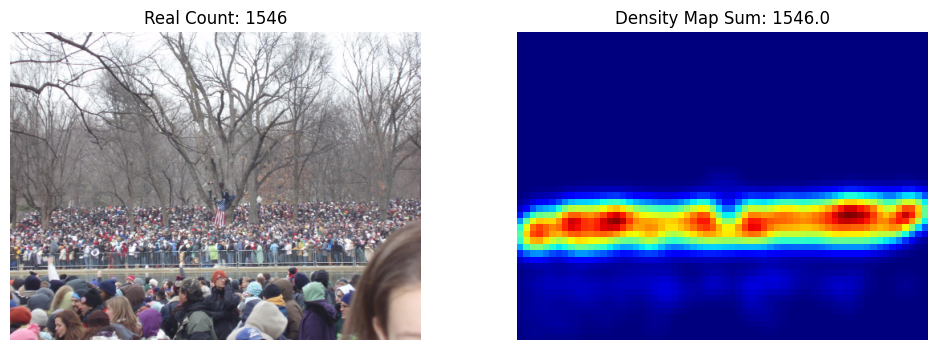

In [ ]:
# The sum of the density map should equal the real count
i = 0
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_train_all[i].astype(np.uint8))
plt.title(f"Real Count: {c_train_all[i]:.0f}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(d_train_all[i, ..., 0], cmap="jet")
plt.title(f"Density Map Sum: {d_train_all[i].sum():.1f}")
plt.axis("off")

plt.show()

## **8. Train/Validation Split**

In [ ]:
# The test set is kept separate and used only for the final evaluation
idx = np.random.permutation(len(x_train_all))
n_val = int(0.1 * len(idx))
val_idx, tr_idx = idx[:n_val], idx[n_val:]

x_train, d_train = x_train_all[tr_idx], d_train_all[tr_idx]
x_val, d_val = x_train_all[val_idx], d_train_all[val_idx]

print("Train:", len(x_train), "| Validation:", len(x_val), "| Test:", len(x_test))

Train: 270 | Validation: 30 | Test: 182


## **9. Preprocessing + Data Pipeline**

In [ ]:
def preprocess_input(x):
    # Same preprocessing as VGG16: RGB to BGR, then subtract the ImageNet mean
    x = x[..., ::-1]
    if isinstance(x, tf.Tensor):
        return x - tf.constant(VGG_MEAN, dtype=x.dtype)
    return x - np.array(VGG_MEAN, dtype=np.float32)

def augment(x, d):
    # Random horizontal flip for both the image and its density map
    if tf.random.uniform(()) > 0.5:
        x = tf.image.flip_left_right(x)
        d = tf.image.flip_left_right(d)
    return x, d

def make_dataset(x, d, training):
    ds = tf.data.Dataset.from_tensor_slices((x, d * SCALE))
    if training:
        ds = ds.shuffle(len(x), seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda img, den: (preprocess_input(img), den), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(4).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(x_train, d_train, training=True)
val_ds = make_dataset(x_val, d_val, training=False)

## **10. Build CSRNet Model**

In [ ]:
def build_model():
    # Front end: first layers of VGG16 pre-trained on ImageNet (output is 8x smaller)
    vgg = VGG16(include_top=False, weights="imagenet", input_shape=(IMG_H, IMG_W, 3))
    front_end = models.Model(vgg.input, vgg.get_layer("block4_conv3").output)

    # Back end: dilated convolutions to capture context without shrinking the map
    inputs = layers.Input((IMG_H, IMG_W, 3))
    x = front_end(inputs)
    for filters in [512, 512, 512, 256, 128, 64]:
        x = layers.Conv2D(filters, 3, padding="same", dilation_rate=2, activation="relu")(x)
    outputs = layers.Conv2D(1, 1, activation="relu")(x)   # Output = density map

    return models.Model(inputs, outputs, name="insiyab_csrnet")

def count_mae(y_true, y_pred):
    # Error in number of people (not in pixels)
    true_count = tf.reduce_sum(y_true, axis=[1, 2, 3]) / SCALE
    pred_count = tf.reduce_sum(y_pred, axis=[1, 2, 3]) / SCALE
    return tf.reduce_mean(tf.abs(true_count - pred_count))

model = build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="mse", metrics=[count_mae])
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "insiyab_csrnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 384, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 48, 64, 512)    │     7,635,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 64, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 64, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 64, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 64, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 64, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 48, 64, 1)      │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,263,489 (62.04 MB)

 Trainable params: 16,263,489 (62.04 MB)

 Non-trainable params: 0 (0.00 B)

## **11. Train the Model (EarlyStopping + Checkpoint)**

In [ ]:
early_stop = EarlyStopping(
    monitor="val_count_mae",
    mode="min",
    patience=15,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "insiyab_density.keras",
    monitor="val_count_mae",
    mode="min",
    save_best_only=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - count_mae: 239.9313 - loss: 714.1311 - val_count_mae: 285.6408 - val_loss: 657.6174
Epoch 2/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 32s 463ms/step - count_mae: 192.8085 - loss: 418.8058 - val_count_mae: 213.5022 - val_loss: 599.5918
Epoch 3/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 32s 471ms/step - count_mae: 174.9713 - loss: 375.3602 - val_count_mae: 153.4790 - val_loss: 553.3649
Epoch 4/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 32s 468ms/step - count_mae: 155.8429 - loss: 327.2797 - val_count_mae: 203.8179 - val_loss: 553.9651
Epoch 5/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 33s 483ms/step - count_mae: 135.7533 - loss: 292.6249 - val_count_mae: 142.2367 - val_loss: 530.0529
Epoch 6/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 33s 487ms/step - count_mae: 133.7004 - loss: 246.3900 - val_count_mae: 136.9177 - val_loss: 436.0933
Epoch 7/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 33s 481ms/step - count_mae: 151.1669 - loss: 231.2156 - val_count_mae: 146.8101 - val_loss: 488.9437
Epoch 8/100
68/68 ━━━━

## **12. Plot Training Curves**

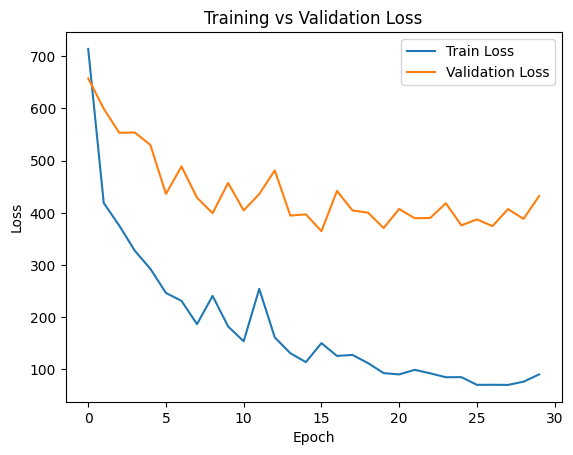

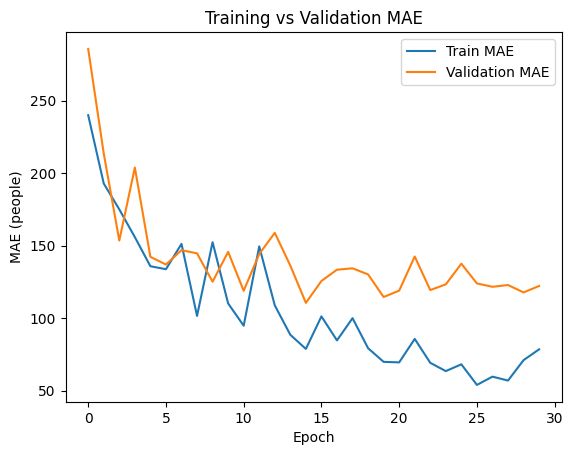

In [ ]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history.history["count_mae"], label="Train MAE")
plt.plot(history.history["val_count_mae"], label="Validation MAE")
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (people)")
plt.legend()
plt.show()

## **13. Evaluate Model on Test Set (MAE, RMSE, MAPE)**

In [ ]:
pred_maps = model.predict(preprocess_input(x_test.copy()), batch_size=4)[..., 0] / SCALE
y_pred = pred_maps.sum(axis=(1, 2))

mae = np.mean(np.abs(y_pred - c_test))
rmse = np.sqrt(np.mean((y_pred - c_test) ** 2))
mape = np.mean(np.abs(y_pred - c_test) / c_test) * 100

print("\n📊 MODEL PERFORMANCE METRICS")
print("------------------------------------")
print(f"MAE  (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"MAPE (Mean Absolute Percentage Error): {mape:.2f}%")
print(f"Average people per test image: {c_test.mean():.0f}")
print("------------------------------------\n")

46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 202ms/step

📊 MODEL PERFORMANCE METRICS
------------------------------------
MAE  (Mean Absolute Error): 93.71
RMSE (Root Mean Squared Error): 160.87
MAPE (Mean Absolute Percentage Error): 23.84%
Average people per test image: 433
------------------------------------



## **14. Define Safety Threshold**

In [ ]:
high_density_threshold = 600   # You can change this value
print(f"High-density threshold set to: {high_density_threshold}")

High-density threshold set to: 600


## **15. Heatmap Overlay on Image**

In [ ]:
def overlay_heatmap(img, density_map):
    density = cv2.resize(density_map, (img.shape[1], img.shape[0]))
    density_norm = density / (density.max() + 1e-9)
    heat = cv2.applyColorMap((density_norm * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)

    overlay = (0.55 * img + 0.45 * heat).astype(np.uint8)
    return overlay

## **16. Display Image + Density Map + Alert**

In [ ]:
def show_full_visualization(idx):
    img = x_test[idx].astype(np.uint8)
    gt = c_test[idx]
    pred = y_pred[idx]
    density = pred_maps[idx]

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title(f"Original Image\nGT: {gt:.0f} | Prediction: {pred:.0f}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(density, cmap="jet")
    plt.title("Predicted Density Map")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay_heatmap(img, density))
    plt.title("Overlay on Image")
    plt.axis("off")

    plt.show()

    # Safety alert for Hajj/Umrah application
    if pred > high_density_threshold:
        print("⚠️ High Crowd Warning: Unsafe density detected!\n")
    else:
        print("✔️ Density Normal.\n")

## **17. Show Multiple Samples**

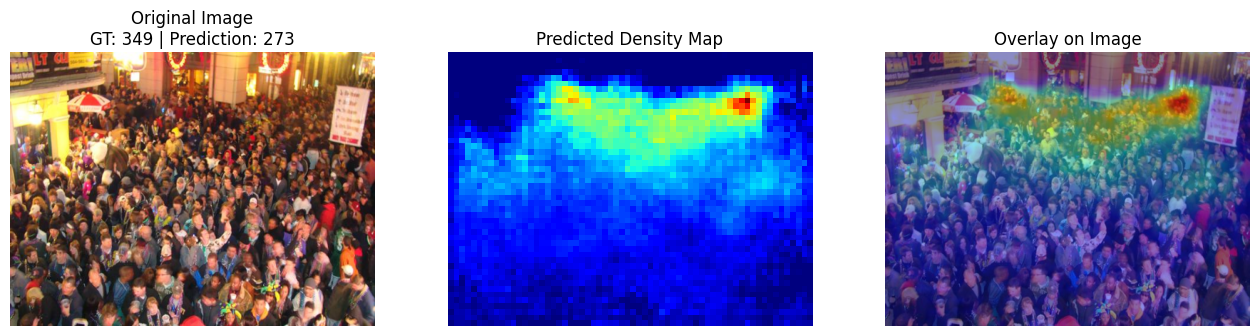

✔️ Density Normal.



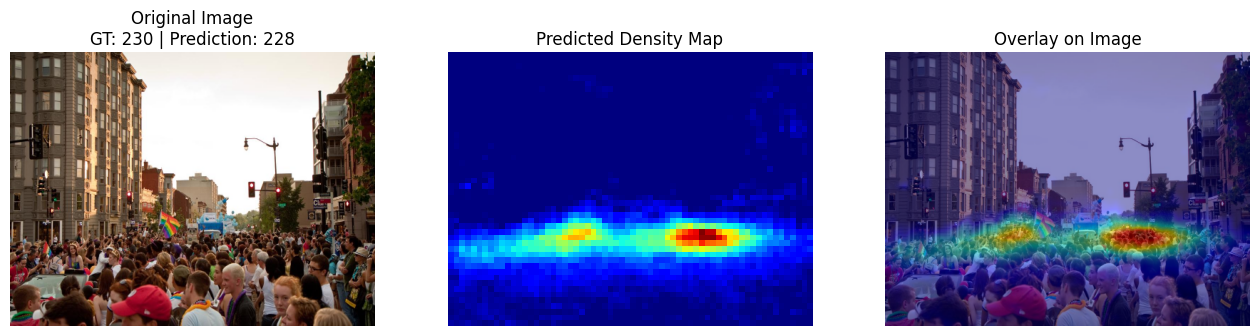

✔️ Density Normal.



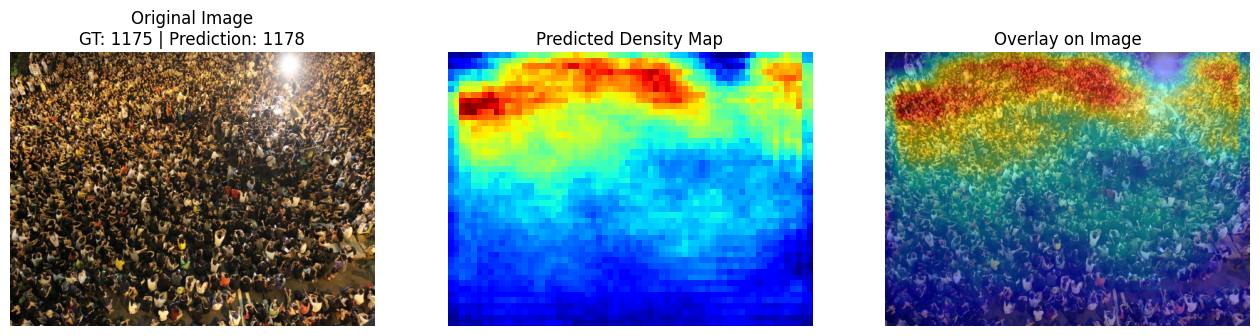

⚠️ High Crowd Warning: Unsafe density detected!



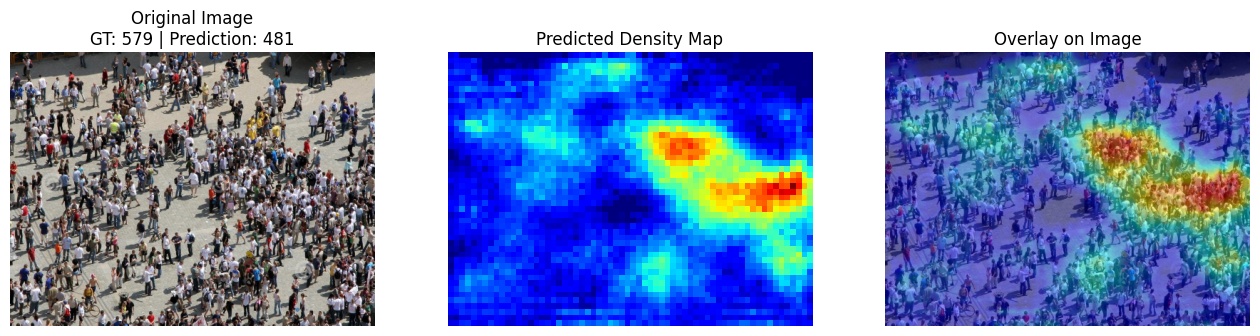

✔️ Density Normal.



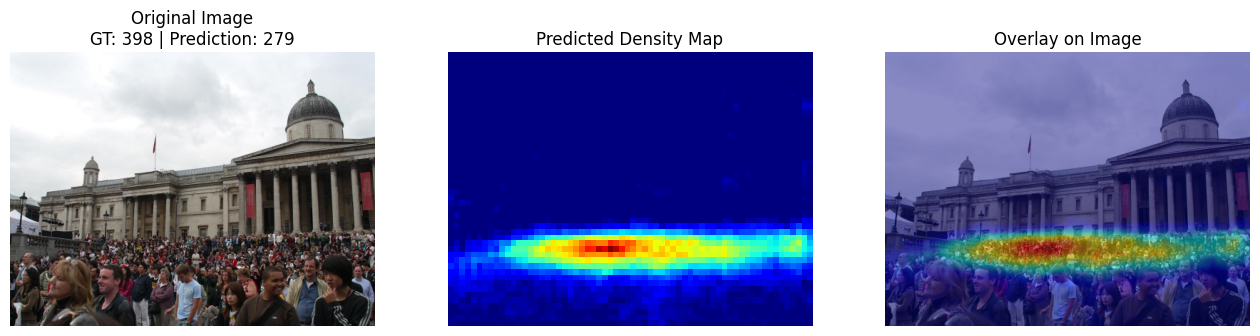

✔️ Density Normal.



In [ ]:
indices = np.random.choice(len(x_test), 5, replace=False)

for idx in indices:
    show_full_visualization(idx)

## **18. Save and Download the Model**

In [ ]:
from google.colab import files

model.save("insiyab_density.keras")
print("Model saved successfully!")
print("Size:", round(os.path.getsize("insiyab_density.keras") / 1e6, 1), "MB")

files.download("insiyab_density.keras")

Model saved successfully!
Size: 195.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **19. Download Demo Images for the App**

In [ ]:
os.makedirs("demo_images", exist_ok=True)

for k, (img_path, _) in enumerate(test_pairs[:6]):
    cv2.imwrite(f"demo_images/zone_{k + 1}.jpg", cv2.imread(img_path))

!zip -qr demo_images.zip demo_images
files.download("demo_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **20. Reduce Model Size for Deployment**

In [ ]:
small = tf.keras.models.load_model("insiyab_density.keras", compile=False)
small.save("insiyab_density.keras")
print("Size:", round(os.path.getsize("insiyab_density.keras") / 1e6, 1), "MB")
files.download("insiyab_density.keras")

Size: 65.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>